In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from datasets import load_dataset



## load dataset



In [3]:
emotion_dataset=load_dataset('dair-ai/emotion')
train_text=emotion_dataset['train']['text']
train_label=emotion_dataset['train']['label']

test_text=emotion_dataset['test']['text']
test_label=emotion_dataset['test']['label']

emotion_dataset

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [4]:
label_names = emotion_dataset['train'].features['label'].names

In [5]:
df_train=pd.DataFrame(
    {
        'text':train_text,
        'label':[label_names[i] for i in train_label]
    }
)

df_test=pd.DataFrame(
    {
        'text':test_text,
        'label':[label_names[i] for i in test_label]
    }
)

In [6]:
df_test.head()

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


## EDA

<Axes: xlabel='label', ylabel='count'>

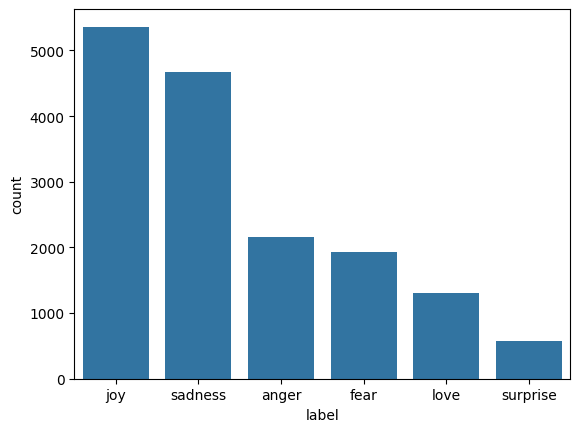

In [7]:
sns.countplot(x='label',data=df_train,order=df_train['label'].value_counts().index)

# preprocessing-NLP

In [8]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words=1000

tokenizer=Tokenizer(num_words=max_words,oov_token='<unk>')
tokenizer.fit_on_texts(df_train['text'])

train_sequence=tokenizer.texts_to_sequences(df_train['text'])
test_sequence=tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence=pad_sequences(train_sequence,maxlen=50,padding='post',truncating='post')
padded_test_sequence=pad_sequences(test_sequence,maxlen=50,padding='post',truncating='post')

train_labels=np.array(train_label)
test_labels=np.array(test_label)

num_classes=len(np.unique(train_labels))
num_classes



6

# Shared training utilities(balanced class)


In [9]:
from sklearn.utils import class_weight

class_weights=class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)

class_weight_dict=dict(enumerate(class_weights))

In [10]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping=EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Phase 1 of RNN

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding,SimpleRNN,Dense,Dropout,LSTM,GRU

rnn_model=Sequential([
    Embedding(
      input_dim=max_words,
      output_dim=128,
      input_length=50
    ),
    SimpleRNN(units=128,return_sequences=True),

    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')

])


rnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [12]:
rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence,test_labels),
    epochs=20,
    batch_size=32,
    validation_split=0.2,

    class_weight=class_weight_dict,
    callbacks=[early_stopping]

)

rnn_loss,rnn_accuracy=rnn_model.evaluate(padded_test_sequence,test_labels)
print(f"rnn loss :{rnn_loss}")
print(f"rnn accuracy:{rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 26s 45ms/step - accuracy: 0.1596 - loss: 1.8994 - val_accuracy: 0.1125 - val_loss: 1.8330
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - accuracy: 0.1500 - loss: 1.8075 - val_accuracy: 0.0765 - val_loss: 1.8151
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - accuracy: 0.1435 - loss: 1.7954 - val_accuracy: 0.2460 - val_loss: 1.7631
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 37ms/step - accuracy: 0.1516 - loss: 1.7918 - val_accuracy: 0.1135 - val_loss: 1.7876
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.1465 - loss: 1.7866 - val_accuracy: 0.1180 - val_loss: 1.7979
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - accuracy: 0.1451 - loss: 1.7826 - val_accuracy: 0.1385 - val_loss: 1.7736
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.2460 - loss: 1.7631
rnn loss :1.7631218433380127
rnn accuracy:0.2460000067949295


# Phase-2(LSTM)

In [13]:
lstm_model=Sequential([
    Embedding(
      input_dim=max_words,
      output_dim=128,
      input_length=50
    ),
    LSTM(units=128,return_sequences=True),

    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')

])


lstm_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence,test_labels),
    epochs=20,
    batch_size=32,

    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

lstm_loss,lstm_accuracy=lstm_model.evaluate(padded_test_sequence,test_labels)
print(f"lstm loss :{lstm_loss}")
print(f"lstm accuracy:{lstm_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 57s 108ms/step - accuracy: 0.1511 - loss: 1.7954 - val_accuracy: 0.0800 - val_loss: 1.7895
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 107ms/step - accuracy: 0.1412 - loss: 1.7936 - val_accuracy: 0.0800 - val_loss: 1.7976
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 56s 112ms/step - accuracy: 0.1513 - loss: 1.7930 - val_accuracy: 0.1110 - val_loss: 1.7833
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.0800 - loss: 1.7895
lstm loss :1.7894607782363892
lstm accuracy:0.07999999821186066


# Phase-3(GRU)

In [14]:
gru_model=Sequential([
    Embedding(
      input_dim=max_words,
      output_dim=128,
      input_length=50
    ),
    GRU(units=128,return_sequences=True),

    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')

])


gru_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence,test_labels),
    epochs=20,
    batch_size=32,

    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)


gru_loss,gru_accuracy=gru_model.evaluate(padded_test_sequence,test_labels)
print(f"gru loss :{gru_loss}")
print(f"gru accuracy:{gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 60s 110ms/step - accuracy: 0.1429 - loss: 1.7965 - val_accuracy: 0.1365 - val_loss: 1.7921
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 46s 91ms/step - accuracy: 0.1491 - loss: 1.7951 - val_accuracy: 0.0805 - val_loss: 1.8173
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 81s 90ms/step - accuracy: 0.1583 - loss: 1.7944 - val_accuracy: 0.2870 - val_loss: 1.7773
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.1365 - loss: 1.7921
gru loss :1.7921441793441772
gru accuracy:0.13650000095367432


# Phase 1 ranking & selection

In [26]:
result_df=pd.DataFrame({
    'Model':['RNN','LSTM','GRU'],
    'Loss':[rnn_loss,lstm_loss,gru_loss],
    'Accuracy':[rnn_accuracy,lstm_accuracy,gru_accuracy]
}).sort_values(by='Accuracy',ascending=False)

result_df

,Model,Loss,Accuracy
0,RNN,1.763122,0.2460
2,GRU,1.792144,0.1365
1,LSTM,1.789461,0.0800


# Phase 2 -Advanced bidirectional GRU

advance stack bidirectional


In [17]:
from tensorflow.keras.layers import Bidirectional

BiGRU=Sequential([
    Embedding(input_dim=max_words,output_dim=300,input_length=50),
    Bidirectional(GRU(128,return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes,activation='softmax')

])


BiGRU.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

BiGRU.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [19]:
BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence,test_labels),
    epochs=20,
    batch_size=32,

    class_weight=class_weight_dict,
    callbacks=[early_stopping]
   )

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 139s 278ms/step - accuracy: 0.9047 - loss: 0.2324 - val_accuracy: 0.8625 - val_loss: 0.4186
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 128s 256ms/step - accuracy: 0.9074 - loss: 0.2217 - val_accuracy: 0.8675 - val_loss: 0.3671
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 140s 252ms/step - accuracy: 0.9172 - loss: 0.1956 - val_accuracy: 0.8600 - val_loss: 0.4188


In [20]:
 BiGRU_loss,BiGRU_accuracy=BiGRU.evaluate(padded_test_sequence,test_labels)
print(f"BiGRU loss :{BiGRU_loss}")
print(f"BiGRU accuracy:{BiGRU_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.8625 - loss: 0.4186
BiGRU loss :0.41862404346466064
BiGRU accuracy:0.862500011920929


Final model confusion matrix


63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 88ms/step


<Axes: >

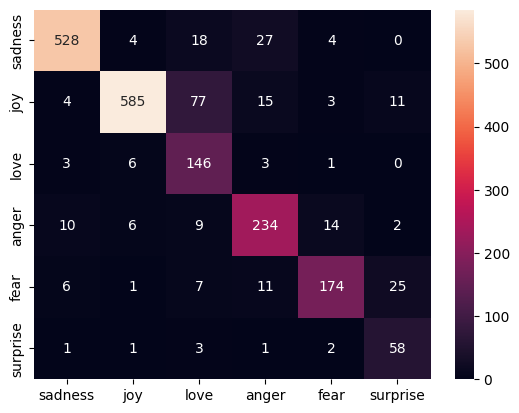

In [21]:
from sklearn.metrics import confusion_matrix

BiGRU_predictions=np.argmax(BiGRU.predict(padded_test_sequence),axis=1)

sns.heatmap(confusion_matrix(test_labels,BiGRU_predictions),annot=True,fmt='d',xticklabels=label_names,yticklabels=label_names)

Final Predictions

In [24]:
sample_texts = [
    "I am feeling very happy today",
    "I am so sad and lonely",
    "I am extremely angry right now",
    "I am scared of what will happen",

]


sample_sequences=tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences=pad_sequences(sample_sequences,maxlen=50,padding='post',truncating='post')

sample_predictions=np.argmax(BiGRU.predict(sample_padded_sequences),axis=1)

for i in range(len(sample_texts)):
  print(f'text:{sample_texts[i]}\nPredicted Emotion:{label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
text:I am feeling very happy today
Predicted Emotion:joy
text:I am so sad and lonely
Predicted Emotion:surprise
text:I am extremely angry right now
Predicted Emotion:anger
text:I am scared of what will happen
Predicted Emotion:fear


# Save the Model

In [30]:
import os
import pickle

model_dir='Artifactes'

os.makedirs(model_dir,exist_ok=True)

#save our BiGRU model


BiGRU.save(os.path.join(model_dir,'BiGRU_model.keras'))

#save the tokenizer model

with open(os.path.join(model_dir,'tokenizer.pkl'),'wb') as file:
  pickle.dump(tokenizer,file)



